<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/2%20-%20Regress%C3%A3o%20Linear/2.4_regressao_linear_autograd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 2.4 — Regressão linear com autograd e `nn.Linear`

## Objetivos

- Calcular o gradiente com o autograd do PyTorch (`requires_grad` e `loss.backward()`), no lugar da derivada escrita à mão no 2.3.
- Criar o modelo com uma camada `nn.Linear`.
- Manter explícitos o cálculo da função de custo (loss) e a atualização dos parâmetros.
- Conferir o gradiente e os parâmetros treinados contra a fórmula e a solução analítica.

O problema é o mesmo dos notebooks 2.2 e 2.3: prever o comprimento da pétala da *Iris versicolor* a partir do comprimento da sépala (50 flores). O modelo é a reta

$$\hat{y} = w_0 + w_1 x$$

em que $x$ é a entrada (comprimento da sépala), $\hat{y}$ é a previsão, $w_0$ é o bias (intercepto) e $w_1$ é o peso. Nos slides, a mesma reta aparece como $h_\theta(x) = \theta_0 + \theta_1 x$: $w_0 = \theta_0$ e $w_1 = \theta_1$.

O que muda em relação ao 2.3:

| Etapa | 2.3 (tensores) | 2.4 (este notebook) |
|---|---|---|
| Modelo | classe `Net` com o tensor `self.w` | `nn.Linear(2, 1, bias=False)` |
| Função de custo | `torch.mean((y_pred - y_train)**2)` | igual |
| Gradiente | fórmula $\frac{2}{M} X^T (X w^T - y)$ | `loss.backward()` (autograd) |
| Atualização | `w = w - lr * w_grad` | igual, dentro de `torch.no_grad()` |

![Fluxo do treinamento](https://raw.githubusercontent.com/vcasadei/images/master/RegressaoLinear_Otimizacao.png)

O fluxo forward vai dos dados ao custo: $x \rightarrow \hat{y} \rightarrow J$. O fluxo backward volta do custo aos parâmetros: o gradiente $\nabla J$ atualiza $w$. Na figura, $\eta$ é a taxa de aprendizado (`lr` no código), $N$ é o número de amostras ($M$ no texto) e $x_0$ é a entrada $x$.

## Importação das bibliotecas

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris

import torch
from torch import nn

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

### Leitura

In [2]:
iris = load_iris()
# classe 1 (versicolor); colunas 0 e 2: comprimento da sépala e comprimento da pétala
data = iris.data[iris.target == 1, ::2]

x_train = data[:, 0:1].astype(np.float32)   # comprimento da sépala
y_train = data[:, 1:2].astype(np.float32)   # comprimento da pétala

n_samples = x_train.shape[0]
print('x_train.shape:', x_train.shape, x_train.dtype)
print('y_train.shape:', y_train.shape, y_train.dtype)

print('x_train[:5]:\n', x_train[:5])
print('y_train[:5]:\n', y_train[:5])

x_train.shape: (50, 1) float32
y_train.shape: (50, 1) float32
x_train[:5]:
 [[7. ]
 [6.4]
 [6.9]
 [5.5]
 [6.5]]
y_train[:5]:
 [[4.7]
 [4.5]
 [4.9]
 [4. ]
 [4.6]]


### Normalização

Como nos notebooks anteriores, cada variável é levada ao intervalo [0, 1] (normalização min-max).

In [3]:
x_train -= x_train.min()
x_train /= x_train.max()
y_train -= y_train.min()
y_train /= y_train.max()

print('x_train[:5]:\n', x_train[:5])
print('y_train[:5]:\n', y_train[:5])

x_train[:5]:
 [[1.        ]
 [0.71428573]
 [0.952381  ]
 [0.28571424]
 [0.7619048 ]]
y_train[:5]:
 [[0.80952376]
 [0.71428573]
 [0.90476197]
 [0.4761905 ]
 [0.7619048 ]]


### Coluna de uns: `x_train_bias`

Como no 2.3, uma coluna de uns à esquerda de `x_train` faz o produto $X w^T$ incluir o bias: cada linha vira $1 \cdot w_0 + x \cdot w_1$. O shape é $(M, 2) = (50, 2)$.

In [4]:
x_train_bias = np.hstack([np.ones(shape=(n_samples, 1)), x_train])
print('x_train_bias.shape:', x_train_bias.shape, x_train_bias.dtype)
x_train_bias[:5]

x_train_bias.shape: (50, 2) float64


array([[1.        , 1.        ],
       [1.        , 0.71428573],
       [1.        , 0.95238101],
       [1.        , 0.28571424],
       [1.        , 0.76190478]])

### Conversão para tensores

`torch.from_numpy(...)` cria um tensor que compartilha memória com o array NumPy; `.float()` converte para `float32`, o tipo dos parâmetros do modelo. Os dados não precisam de gradiente, então são tensores comuns (`requires_grad=False`).

Versões do PyTorch anteriores à 0.4 exigiam embrulhar os tensores em `torch.autograd.Variable` para usar o autograd. Desde a 0.4, o próprio tensor participa do autograd e `Variable` é obsoleto: não use.

In [5]:
x_train_bias = torch.from_numpy(x_train_bias).float()
y_train = torch.from_numpy(y_train)   # já é float32
print('x_train_bias:', x_train_bias.shape, x_train_bias.dtype, 'requires_grad =', x_train_bias.requires_grad)
print('y_train:     ', y_train.shape, y_train.dtype)

x_train_bias: torch.Size([50, 2]) torch.float32 requires_grad = False
y_train:      torch.Size([50, 1]) torch.float32


## Modelo

![Neurônio da regressão linear](https://raw.githubusercontent.com/vcasadei/images/master/RegressaoLinearNeuronio.png)

`nn.Linear(in_features=2, out_features=1, bias=False)` é uma camada do PyTorch que calcula $\hat{y} = X W^T$:

- `model.weight` tem shape $(1, 2)$ e guarda $[w_0, w_1]$, os mesmos 2 parâmetros do 2.3;
- `bias=False` porque a coluna de uns de `x_train_bias` já faz o papel do bias $w_0$ (no 2.6 usaremos o bias da própria camada);
- `model.weight` é um `nn.Parameter`: um tensor com `requires_grad=True`. Isso pede ao autograd que registre as operações feitas com ele, para depois calcular o gradiente do custo em relação a ele.

`model` é o nome da variável; `nn.Linear`, `weight` e `requires_grad` são do PyTorch.

In [10]:
model = nn.Linear(in_features=2, out_features=1, bias=False)
print(model)
print('weight.shape:', model.weight.shape)
print('requires_grad:', model.weight.requires_grad)

Linear(in_features=2, out_features=1, bias=False)
weight.shape: torch.Size([1, 2])
requires_grad: True


In [11]:
model.weight

Parameter containing:
tensor([[-0.6247,  0.2838]], requires_grad=True)

### Inicialização dos parâmetros

O `nn.Linear` já inicializa os pesos com valores aleatórios. Para partir do mesmo intervalo do 2.3, reinicializamos com distribuição uniforme em $[-0{,}1;\ 0{,}1]$. `nn.init.uniform_` altera o tensor no lugar (o `_` no final indica operação in-place) sem registrar a operação no autograd.

In [14]:
nn.init.uniform_(model.weight, -0.1, 0.1)
model.weight

Parameter containing:
tensor([[0.0567, 0.0126]], requires_grad=True)

### Testando o predict da rede

Com entrada de uns, cada saída vale $w_0 + w_1$. O shape da saída é (5, 1): uma previsão por amostra.

In [15]:
xx = torch.ones((5, 2))
model(xx)

tensor([[0.0694],
        [0.0694],
        [0.0694],
        [0.0694],
        [0.0694]], grad_fn=<MmBackward0>)

In [16]:
model(x_train_bias)

tensor([[0.0694],
        [0.0658],
        [0.0688],
        [0.0603],
        [0.0664],
        [0.0615],
        [0.0652],
        [0.0567],
        [0.0670],
        [0.0585],
        [0.0573],
        [0.0627],
        [0.0633],
        [0.0639],
        [0.0609],
        [0.0676],
        [0.0609],
        [0.0621],
        [0.0645],
        [0.0609],
        [0.0627],
        [0.0639],
        [0.0652],
        [0.0639],
        [0.0658],
        [0.0670],
        [0.0682],
        [0.0676],
        [0.0633],
        [0.0615],
        [0.0603],
        [0.0603],
        [0.0621],
        [0.0633],
        [0.0597],
        [0.0633],
        [0.0676],
        [0.0652],
        [0.0609],
        [0.0603],
        [0.0603],
        [0.0639],
        [0.0621],
        [0.0573],
        [0.0609],
        [0.0615],
        [0.0615],
        [0.0645],
        [0.0579],
        [0.0615]], grad_fn=<MmBackward0>)

A saída mostra `grad_fn=<MmBackward0>`: o autograd anotou que esse tensor veio de uma multiplicação de matrizes envolvendo `model.weight`. É essa anotação (o grafo computacional) que `backward()` percorre de trás para frente.

### O autograd num passo

Antes do laço, um passo isolado: calculamos o custo, chamamos `loss.backward()` e comparamos o gradiente que o autograd colocou em `model.weight.grad` com a fórmula do 2.3,

$$\nabla_w J = \frac{2}{M} X^T (X w^T - y),$$

em que $X$ é `x_train_bias` e $M = 50$.

In [17]:
y_pred = model(x_train_bias)                  # forward: (50, 1)
loss = torch.mean((y_pred - y_train) ** 2)    # função de custo: tensor escalar
print('loss:', loss)

loss.backward()                               # backward: preenche model.weight.grad
print('gradiente (autograd):', model.weight.grad)

# mesmo gradiente pela fórmula do 2.3 (só conta; não precisa de grafo)
with torch.no_grad():
    w_grad = (2.0 / n_samples) * x_train_bias.t().mm(x_train_bias.mm(model.weight.t()) - y_train)
print('gradiente (fórmula): ', w_grad.t())

model.weight.grad.zero_()   # zera o gradiente antes do treino
print('gradiente zerado:   ', model.weight.grad)

loss: tensor(0.3365, grad_fn=<MeanBackward0>)
gradiente (autograd): tensor([[-1.0741, -0.6097]])
gradiente (fórmula):  tensor([[-1.0741, -0.6097]])
gradiente zerado:    tensor([[0., 0.]])


## Treinamento

A função de custo é o erro quadrático médio (MSE), a mesma do 2.3:

$$J(w) = \frac{1}{M}\sum_{i=1}^{M}\left(\hat{y}^{(i)} - y^{(i)}\right)^2$$

Nos slides, $J$ tem o fator $\frac{1}{2m}$ em vez de $\frac{1}{M}$. A diferença só multiplica o gradiente por 2: o mínimo é o mesmo.

A cada época (epoch), que aqui é uma passada por todas as 50 amostras:

1. forward: calcula `y_pred` e o custo `loss` com os parâmetros atuais;
2. `loss.backward()`: o autograd calcula $\nabla_w J$ e guarda em `model.weight.grad`;
3. atualização: $w \leftarrow w - \text{lr} \cdot \nabla_w J$. Ela é feita dentro de `with torch.no_grad():` porque a própria atualização não deve entrar no grafo do autograd;
4. `model.weight.grad.zero_()`: o PyTorch acumula (soma) gradientes a cada `backward()`; sem zerar, a época seguinte somaria o gradiente novo ao antigo.

Mudam os parâmetros `model.weight` e o gradiente; ficam fixos os dados e a taxa de aprendizado (learning rate) `lr`. O valor do custo é guardado com `loss.item()`, que devolve um número Python (veja o Exercício 1).

In [18]:
n_epochs = 100
lr = 0.5
losses = []

for epoch in range(n_epochs):
    # forward: previsão e função de custo
    y_pred = model(x_train_bias)
    loss = torch.mean((y_pred - y_train) ** 2)

    # backward: o autograd calcula d(loss)/d(weight) e guarda em model.weight.grad
    loss.backward()

    # gradiente descendente: atualização manual, fora do grafo do autograd
    with torch.no_grad():
        model.weight -= lr * model.weight.grad

    # zera o gradiente acumulado para a próxima época
    model.weight.grad.zero_()

    losses.append(loss.item())   # .item(): número Python, sem histórico de gradiente
    if (epoch + 1) % 20 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], loss: {loss.item():.6f}')

Epoch[20/100], loss: 0.023083
Epoch[40/100], loss: 0.021446
Epoch[60/100], loss: 0.021210
Epoch[80/100], loss: 0.021175
Epoch[100/100], loss: 0.021170


In [ ]:
plt.plot(losses)
plt.xlabel('época')
plt.ylabel('função de custo (MSE)')
plt.title('Custo durante o treinamento')
plt.show()

## Avaliação

Para só prever, usamos `torch.no_grad()`: o autograd não registra o grafo, e a saída pode ir direto para NumPy.

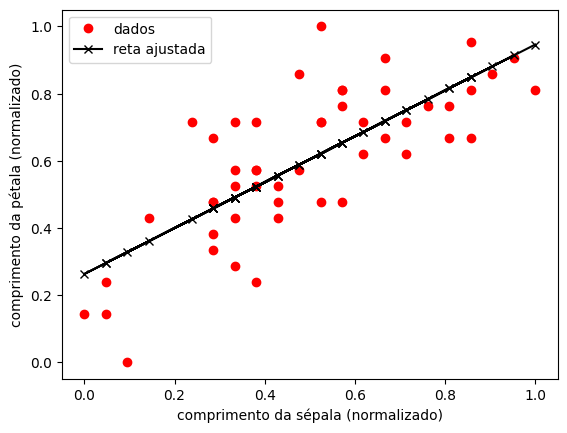

In [19]:
with torch.no_grad():
    y_pred = model(x_train_bias)

plt.plot(x_train, y_train.numpy(), 'ro', label='dados')
plt.plot(x_train, y_pred.numpy(), 'kx-', label='reta ajustada')
plt.xlabel('comprimento da sépala (normalizado)')
plt.ylabel('comprimento da pétala (normalizado)')
plt.legend()
plt.show()

### Acessando os parâmetros

`model.state_dict()` devolve um dicionário com o nome e o valor de cada parâmetro da camada. Aqui há um só, `weight`, com $[w_0, w_1]$.

In [20]:
w_dic = model.state_dict()
w_dic

OrderedDict([('weight', tensor([[0.2632, 0.6829]]))])

### Parâmetros ótimos: solução analítica

A equação normal, vista no 2.2, dá os parâmetros que minimizam o MSE diretamente:

$$w^* = (X^T X)^{-1} X^T y$$

com $X$ = `x_train_bias` (shape (50, 2)) e $y$ = `y_train` (shape (50, 1)). O resultado treinado deve ficar próximo de $w^*$.

In [21]:
x_bias = x_train_bias
y = y_train
x_bias_t = x_bias.t()
w_opt = torch.inverse(x_bias_t.mm(x_bias)).mm(x_bias_t).mm(y)
print('w_opt (analítico):', w_opt.t())
print('w treinado:       ', model.weight.detach())

w_opt (analítico): tensor([[0.2613, 0.6865]])
w treinado:        tensor([[0.2632, 0.6829]])


## Exercícios

### Exercício 1 — `loss`, `loss.detach()` e `loss.item()`

No laço de treinamento, o valor da função de custo é impresso e guardado em `losses` com `loss.item()`. Execute a célula abaixo e compare os três objetos.

a) Que tipo de objeto cada um devolve? Qual deles carrega `grad_fn`?

b) Por que não guardar `loss` diretamente na lista `losses`?

c) Versões antigas deste notebook imprimiam `loss.data`. O que `.data` fazia e por que hoje se usa `.item()` ou `.detach()`?

In [ ]:
print(type(loss), loss)
print(type(loss.detach()), loss.detach())
print(type(loss.item()), loss.item())

**Resposta:**

*Escreva sua resposta aqui.*

### Exercício 2 — Custo final

Calcule o valor da função de custo (MSE) usando o modelo já treinado e guarde em `mse`; calcule também o MSE dos parâmetros ótimos e guarde em `mse_opt` (a célula imprime os dois). Compare com o último valor guardado no laço de treinamento (`losses[-1]`) e com `mse_opt`. Por que o valor calculado aqui não é exatamente igual a `losses[-1]`?

In [ ]:
# TODO: escreva sua solução aqui
print(f'MSE do modelo treinado:  {mse.item():.8f}')
print(f'último valor do laço:     {losses[-1]:.8f}')
print(f'MSE da solução analítica: {mse_opt.item():.8f}')

**Resposta:**

*Escreva sua resposta aqui.*

### Exercício 3 — Trajetória dos parâmetros

Crie duas listas, `w0_list` e `w1_list`, para guardar os valores de $w_0$ e $w_1$ a cada época do treinamento. Reinicialize os pesos com `nn.init.uniform_(model.weight, -0.1, 0.1)` para ver a trajetória desde o início e repita o laço de treinamento, guardando os parâmetros antes de cada atualização (use `.item()`).

Depois, adapte o exemplo de gráfico abaixo (scatter plot com setas) para mostrar o caminho de $(w_0, w_1)$ no plano, e marque o valor ótimo `w_opt` dado pela solução analítica.

Exemplo de scatter plot com setas entre pontos consecutivos:

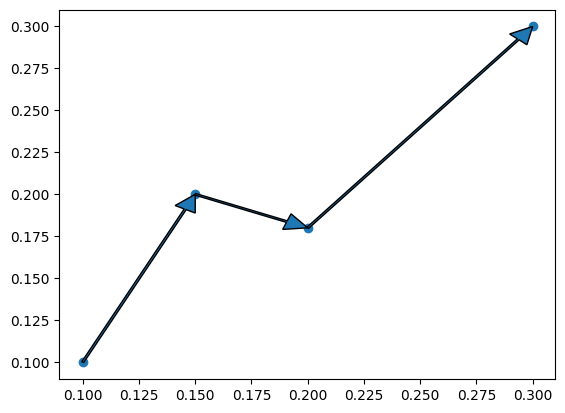

In [22]:
# Exemplo
w0_list = [0.1, 0.15, 0.2, 0.3]
w1_list = [0.1, 0.2, 0.18, 0.3]
plt.scatter(w0_list, w1_list)
w0_old = None
for (w0, w1) in zip(w0_list, w1_list):
    if w0_old is not None:
        plt.arrow(w0_old, w1_old, w0 - w0_old, w1 - w1_old,
                  head_length=0.01, head_width=0.01, shape='full',
                  length_includes_head=True)
    w0_old, w1_old = w0, w1
plt.show()

In [ ]:
w0_list = []
w1_list = []
# TODO: escreva sua solução aqui


## Aprendizados

- Com `requires_grad=True`, o PyTorch registra as operações num grafo e `loss.backward()` calcula o gradiente do custo: é o mesmo valor da fórmula escrita à mão no 2.3.
- `nn.Linear(2, 1, bias=False)` guarda os parâmetros $[w_0, w_1]$ em `model.weight`, de shape (1, 2); $w_0$ e $w_1$ correspondem a $\theta_0$ e $\theta_1$ dos slides.
- A atualização manual dos parâmetros fica dentro de `torch.no_grad()`, e o gradiente é zerado a cada época porque o PyTorch o acumula.
- `.item()` devolve um número Python e `.detach()` um tensor sem histórico; `Variable` e `.data` são de versões antigas do PyTorch.
- O mesmo `loss.backward()` calcula os gradientes no treino de um LLM, com bilhões de parâmetros em vez de 2.